# LAB 04 - Text Classification

Dataset: NLTK movie_reviews (2000 review phim, nhãn pos/neg cân bằng, cùng nguồn với IMDb). Bài toán sentiment classification (Option A).

In [1]:
import time
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from sklearn.metrics.pairwise import cosine_similarity
from gensim.models import Word2Vec

from preprocessing import load_movie_reviews, stratified_split, clean_text, tokenize, ID2LABEL

RESULTS = []


def log(experiment, setting, item, metric, value):
    RESULTS.append(dict(experiment=experiment, setting=setting, item=item, metric=metric, value=value))


def evaluate(name, y_true, y_pred):
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred)
    rec = recall_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)
    print(f"{name}: accuracy={acc:.4f} precision={prec:.4f} recall={rec:.4f} f1={f1:.4f}")
    return acc, prec, rec, f1

## Experiment 1 - Dataset inspection

Kiểm tra số sample, số class, class distribution, độ dài document, duplicate, missing text/label trước khi train.

In [2]:
texts, labels = load_movie_reviews()
n = len(texts)
n_pos = sum(labels)
n_neg = n - n_pos
lengths = [len(tokenize(t)) for t in texts]
dupes = n - len(set(texts))
missing_text = sum(1 for t in texts if not t.strip())

print("Số sample:", n)
print("Số class:", len(set(labels)), "-", Counter(labels))
print(f"Tỷ lệ pos/neg: {n_pos/n*100:.1f}% / {n_neg/n*100:.1f}%")
print(f"Độ dài document (token): mean={np.mean(lengths):.1f}, median={np.median(lengths):.0f}, "
      f"min={min(lengths)}, max={max(lengths)}")
print("Document trùng lặp:", dupes)
print("Document rỗng (missing text):", missing_text)
print("Nhãn thiếu (missing label):", sum(1 for l in labels if l not in (0, 1)))

log("exp1", "full", "n_samples", "count", n)
log("exp1", "full", "n_pos", "count", n_pos)
log("exp1", "full", "n_neg", "count", n_neg)
log("exp1", "full", "pos_pct", "percentage", round(n_pos / n * 100, 2))
log("exp1", "full", "neg_pct", "percentage", round(n_neg / n * 100, 2))
log("exp1", "full", "doc_length_mean", "tokens", round(float(np.mean(lengths)), 2))
log("exp1", "full", "doc_length_median", "tokens", float(np.median(lengths)))
log("exp1", "full", "doc_length_min", "tokens", int(min(lengths)))
log("exp1", "full", "doc_length_max", "tokens", int(max(lengths)))
log("exp1", "full", "duplicates", "count", dupes)
log("exp1", "full", "missing_text", "count", missing_text)

Số sample: 2000
Số class: 2 - Counter({0: 1000, 1: 1000})
Tỷ lệ pos/neg: 50.0% / 50.0%
Độ dài document (token): mean=652.0, median=612, min=16, max=2390
Document trùng lặp: 0
Document rỗng (missing text): 0
Nhãn thiếu (missing label): 0


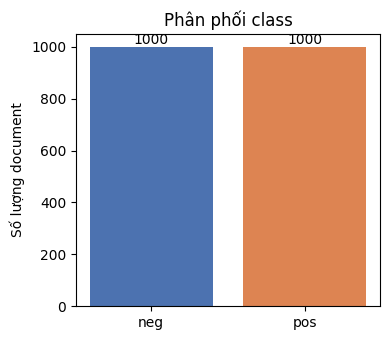

In [3]:
fig, ax = plt.subplots(figsize=(4, 3.5))
ax.bar(["neg", "pos"], [n_neg, n_pos], color=["#4c72b0", "#dd8452"])
ax.set_ylabel("Số lượng document")
ax.set_title("Phân phối class")
for i, v in enumerate([n_neg, n_pos]):
    ax.text(i, v + 10, str(v), ha="center")
fig.tight_layout()
fig.savefig("class_distribution.png", dpi=150)
plt.show()

Dataset cân bằng tuyệt đối (1000 pos / 1000 neg, 50% / 50%), không imbalance. Không có document trùng lặp hoặc rỗng, không có nhãn thiếu.

## Train / Validation / Test split và data leakage

Chia stratified 70/15/15 theo nhãn TRƯỚC khi fit bất kỳ vectorizer nào. TF-IDF và Word2Vec chỉ fit trên train, validation/test chỉ transform.

Nếu fit TF-IDF trên toàn bộ dataset rồi mới split thì vocabulary và IDF đã được tính từ cả các document của test set. Model đã dùng thông tin thống kê của test set trước khi đánh giá nên điểm số không còn phản ánh đúng khả năng generalize.

In [4]:
(train_x, train_y), (val_x, val_y), (test_x, test_y) = stratified_split(texts, labels, seed=42)
print("Train/Val/Test size:", len(train_x), len(val_x), len(test_x))
print("Train class balance:", Counter(train_y))
print("Val class balance:", Counter(val_y))
print("Test class balance:", Counter(test_y))

log("split", "train", "size", "count", len(train_x))
log("split", "val", "size", "count", len(val_x))
log("split", "test", "size", "count", len(test_x))

train_x_clean = [clean_text(t) for t in train_x]
val_x_clean = [clean_text(t) for t in val_x]
test_x_clean = [clean_text(t) for t in test_x]

Train/Val/Test size: 1400 300 300
Train class balance: Counter({0: 700, 1: 700})
Val class balance: Counter({0: 150, 1: 150})
Test class balance: Counter({1: 150, 0: 150})


## Core implementation và Experiment 2 - Baseline (TF-IDF + Logistic Regression)

In [5]:
t0 = time.time()
vec = TfidfVectorizer()
Xtr = vec.fit_transform(train_x_clean)
Xte = vec.transform(test_x_clean)
vocab_size = len(vec.vocabulary_)

clf = LogisticRegression(max_iter=1000)
clf.fit(Xtr, train_y)
train_time = time.time() - t0

baseline_pred = clf.predict(Xte)
acc, prec, rec, f1 = evaluate("TF-IDF + Logistic Regression (baseline)", test_y, baseline_pred)
print("Vocabulary size:", vocab_size)
print(f"Training time: {train_time:.3f}s")

log("exp2", "tfidf_lr", "vocab_size", "count", vocab_size)
log("exp2", "tfidf_lr", "training_time", "seconds", round(train_time, 4))
for m, v in [("accuracy", acc), ("precision", prec), ("recall", rec), ("f1", f1)]:
    log("exp2", "tfidf_lr", m, "score", round(float(v), 4))
    log("exp3", "tfidf_lr", m, "score", round(float(v), 4))

TF-IDF + Logistic Regression (baseline): accuracy=0.8067 precision=0.7949 recall=0.8267 f1=0.8105
Vocabulary size: 33734
Training time: 0.732s


## Experiment 3 - Representation comparison

Model A: TF-IDF + Logistic Regression (chính là baseline). Model B: Average Word2Vec + Logistic Regression. Model C: TF-IDF + Linear SVM.

In [6]:
t0 = time.time()
train_tokens = [tokenize(t) for t in train_x_clean]
test_tokens = [tokenize(t) for t in test_x_clean]
w2v = Word2Vec(sentences=train_tokens, vector_size=100, window=5, min_count=2,
               sg=0, negative=5, epochs=10, seed=42, workers=1)
w2v_train_time = time.time() - t0


def doc_vector(tokens, model):
    vecs = [model.wv[w] for w in tokens if w in model.wv]
    if not vecs:
        return np.zeros(model.vector_size)
    return np.mean(vecs, axis=0)


Xtr_w2v = np.array([doc_vector(toks, w2v) for toks in train_tokens])
Xte_w2v = np.array([doc_vector(toks, w2v) for toks in test_tokens])

t0 = time.time()
clf_w2v = LogisticRegression(max_iter=1000)
clf_w2v.fit(Xtr_w2v, train_y)
w2v_lr_time = time.time() - t0 + w2v_train_time

pred_w2v = clf_w2v.predict(Xte_w2v)
acc2, prec2, rec2, f12 = evaluate("Average Word2Vec + Logistic Regression", test_y, pred_w2v)

log("exp3", "w2v_lr", "vocab_size", "count", len(w2v.wv))
log("exp3", "w2v_lr", "training_time", "seconds", round(w2v_lr_time, 4))
for m, v in [("accuracy", acc2), ("precision", prec2), ("recall", rec2), ("f1", f12)]:
    log("exp3", "w2v_lr", m, "score", round(float(v), 4))

Average Word2Vec + Logistic Regression: accuracy=0.6967 precision=0.6928 recall=0.7067 f1=0.6997


In [7]:
t0 = time.time()
clf_svm = LinearSVC()
clf_svm.fit(Xtr, train_y)
svm_time = time.time() - t0

pred_svm = clf_svm.predict(Xte)
acc3, prec3, rec3, f13 = evaluate("TF-IDF + Linear SVM", test_y, pred_svm)

log("exp3", "tfidf_svm", "vocab_size", "count", vocab_size)
log("exp3", "tfidf_svm", "training_time", "seconds", round(svm_time, 4))
for m, v in [("accuracy", acc3), ("precision", prec3), ("recall", rec3), ("f1", f13)]:
    log("exp3", "tfidf_svm", m, "score", round(float(v), 4))

TF-IDF + Linear SVM: accuracy=0.8300 precision=0.8113 recall=0.8600 f1=0.8350


In [8]:
comparison = pd.DataFrame({
    "representation": ["TF-IDF", "Avg Word2Vec", "TF-IDF"],
    "classifier": ["Logistic Regression", "Logistic Regression", "Linear SVM"],
    "accuracy": [acc, acc2, acc3],
    "precision": [prec, prec2, prec3],
    "recall": [rec, rec2, rec3],
    "f1": [f1, f12, f13],
})
comparison

,representation,classifier,accuracy,precision,recall,f1
0,TF-IDF,Logistic Regression,0.806667,0.794872,0.826667,0.810458
1,Avg Word2Vec,Logistic Regression,0.696667,0.692810,0.706667,0.699670
2,TF-IDF,Linear SVM,0.830000,0.811321,0.860000,0.834951


TF-IDF + Logistic Regression và TF-IDF + Linear SVM cho F1 cao hơn rõ rệt so với Average Word2Vec + Logistic Regression.

Lý do: TF-IDF là sparse, lexical, giữ thông tin từng term (bad, worst, boring là các feature độc lập với trọng số riêng), phù hợp với sentiment vì cảm xúc thường thể hiện qua các từ đặc trưng. Average Word2Vec là dense, semantic nhưng lấy trung bình vector của mọi từ trong document (trung bình hơn 600 token) nên tín hiệu của vài từ sentiment mạnh bị loãng bởi hàng trăm từ trung tính. Word2Vec còn mất word order và mỗi từ chỉ có một vector.

## Experiment 4 - Word order

So sánh hai câu chỉ khác nhau ở từ "not".

In [9]:
s1 = "this movie is good"
s2 = "this movie is not good"
t1, t2 = tokenize(s1), tokenize(s2)

v1, v2 = doc_vector(t1, w2v), doc_vector(t2, w2v)
cos_w2v = float(np.dot(v1, v2) / (np.linalg.norm(v1) * np.linalg.norm(v2) + 1e-9))

tfidf_s1, tfidf_s2 = vec.transform([s1]), vec.transform([s2])
cos_tfidf = float(cosine_similarity(tfidf_s1, tfidf_s2)[0][0])

prob1_lr = float(clf.predict_proba(tfidf_s1)[0][1])
prob2_lr = float(clf.predict_proba(tfidf_s2)[0][1])
prob1_w2v = float(clf_w2v.predict_proba(v1.reshape(1, -1))[0][1])
prob2_w2v = float(clf_w2v.predict_proba(v2.reshape(1, -1))[0][1])

print(f"Cosine similarity avg-Word2Vec(s1, s2) = {cos_w2v:.4f}")
print(f"Cosine similarity TF-IDF(s1, s2)       = {cos_tfidf:.4f}")
print(f"P(positive | s1) với TF-IDF+LR  = {prob1_lr:.4f}, P(positive | s2) = {prob2_lr:.4f}")
print(f"P(positive | s1) với AvgW2V+LR  = {prob1_w2v:.4f}, P(positive | s2) = {prob2_w2v:.4f}")

log("exp4", "word_order", "cosine_avgw2v_s1_s2", "similarity", round(cos_w2v, 4))
log("exp4", "word_order", "cosine_tfidf_s1_s2", "similarity", round(cos_tfidf, 4))
log("exp4", "word_order", "P_pos_s1_tfidf_lr", "probability", round(prob1_lr, 4))
log("exp4", "word_order", "P_pos_s2_tfidf_lr", "probability", round(prob2_lr, 4))
log("exp4", "word_order", "P_pos_s1_w2v_lr", "probability", round(prob1_w2v, 4))
log("exp4", "word_order", "P_pos_s2_w2v_lr", "probability", round(prob2_w2v, 4))

Cosine similarity avg-Word2Vec(s1, s2) = 0.9490
Cosine similarity TF-IDF(s1, s2)       = 0.9014
P(positive | s1) với TF-IDF+LR  = 0.3822, P(positive | s2) = 0.3818
P(positive | s1) với AvgW2V+LR  = 0.7300, P(positive | s2) = 0.4759


Với average embeddings, "not" chỉ là một vector cộng vào trung bình như mọi từ khác, không có cơ chế đảo ngược nghĩa của "good". Cosine similarity giữa hai câu rất cao nên hai câu gần như không được phân biệt, và xác suất dự đoán của hai câu không đảo ngược nhau một cách đáng tin cậy. Đây là giới hạn của bag-of-words và averaged embeddings: không mô hình hóa thứ tự hay cấu trúc cú pháp nên không hiểu vai trò phủ định của "not".

## Experiment 5 - N-gram features

In [10]:
t0 = time.time()
vec_uni = TfidfVectorizer()
Xtr_uni = vec_uni.fit_transform(train_x_clean)
Xte_uni = vec_uni.transform(test_x_clean)
clf_uni = LogisticRegression(max_iter=1000)
clf_uni.fit(Xtr_uni, train_y)
time_uni = time.time() - t0
f1_uni = f1_score(test_y, clf_uni.predict(Xte_uni))

t0 = time.time()
vec_bi = TfidfVectorizer(ngram_range=(1, 2))
Xtr_bi = vec_bi.fit_transform(train_x_clean)
Xte_bi = vec_bi.transform(test_x_clean)
clf_bi = LogisticRegression(max_iter=1000)
clf_bi.fit(Xtr_bi, train_y)
time_bi = time.time() - t0
f1_bi = f1_score(test_y, clf_bi.predict(Xte_bi))

ngram_table = pd.DataFrame({
    "features": ["Unigram", "Uni + Bigram"],
    "vocabulary": [len(vec_uni.vocabulary_), len(vec_bi.vocabulary_)],
    "f1": [f1_uni, f1_bi],
    "training_time_s": [time_uni, time_bi],
})
print(ngram_table)

log("exp5", "unigram", "vocab_size", "count", len(vec_uni.vocabulary_))
log("exp5", "unigram", "f1", "score", round(float(f1_uni), 4))
log("exp5", "unigram", "training_time", "seconds", round(time_uni, 4))
log("exp5", "uni_bigram", "vocab_size", "count", len(vec_bi.vocabulary_))
log("exp5", "uni_bigram", "f1", "score", round(float(f1_bi), 4))
log("exp5", "uni_bigram", "training_time", "seconds", round(time_bi, 4))

       features  vocabulary        f1  training_time_s
0       Unigram       33734  0.810458         0.622977
1  Uni + Bigram      408277  0.807339         2.108189


Bigram giúp bắt các cụm có nghĩa khác từng từ riêng lẻ, ví dụ "not good" và "very good" trở thành hai feature khác nhau thay vì bị gộp vào "not", "good", "very". Tuy nhiên số bigram tăng rất nhanh theo kích thước vocabulary (từ hàng chục nghìn lên hàng trăm nghìn feature), ma trận thưa hơn, training chậm hơn, và nhiều bigram hiếm không đủ dữ liệu để học trọng số ổn định nên có thể overfit. Trong thí nghiệm này F1 không cải thiện.

## Evaluation - Confusion matrix (TF-IDF + Logistic Regression trên test set)

Confusion matrix:
 [[118  32]
 [ 26 124]]
TP=124 FN=26 FP=32 TN=118


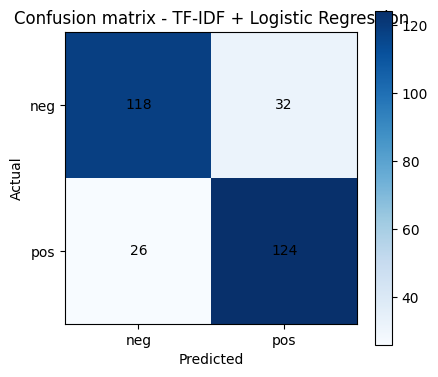

In [11]:
cm = confusion_matrix(test_y, baseline_pred)
tn, fp, fn, tp = cm.ravel()
print("Confusion matrix:\n", cm)
print(f"TP={tp} FN={fn} FP={fp} TN={tn}")

log("eval", "tfidf_lr_test", "TP", "count", int(tp))
log("eval", "tfidf_lr_test", "FP", "count", int(fp))
log("eval", "tfidf_lr_test", "FN", "count", int(fn))
log("eval", "tfidf_lr_test", "TN", "count", int(tn))

fig, ax = plt.subplots(figsize=(4.5, 4))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks([0, 1]); ax.set_xticklabels(["neg", "pos"])
ax.set_yticks([0, 1]); ax.set_yticklabels(["neg", "pos"])
ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
ax.set_title("Confusion matrix - TF-IDF + Logistic Regression")
for i in range(2):
    for j in range(2):
        ax.text(j, i, str(cm[i, j]), ha="center", va="center", color="black")
fig.colorbar(im)
fig.tight_layout()
fig.savefig("confusion_matrix.png", dpi=150)
plt.show()

Hai loại lỗi gần tương đương (32 FP, 26 FN). Model hơi thiên về dự đoán pos nên precision (0.7949) thấp hơn recall (0.8267), nhưng chênh lệch nhỏ, không có class nào bị bỏ sót rõ rệt.

## Error analysis

3 ví dụ phân loại đúng và 3 ví dụ phân loại sai từ test set. Phân tích chi tiết ở error_analysis.md.

In [12]:
correct_idx = [i for i in range(len(test_y)) if test_y[i] == baseline_pred[i]]
wrong_idx = [i for i in range(len(test_y)) if test_y[i] != baseline_pred[i]]

rng = np.random.RandomState(42)
chosen_correct = rng.choice(correct_idx, size=3, replace=False)
chosen_wrong = rng.choice(wrong_idx, size=3, replace=False)

print("Ví dụ phân loại ĐÚNG:")
for i in chosen_correct:
    print(f"- true={ID2LABEL[test_y[i]]} pred={ID2LABEL[baseline_pred[i]]}: {test_x[i][:150].strip()!r}")

print("\nVí dụ phân loại SAI:")
for i in chosen_wrong:
    print(f"- true={ID2LABEL[test_y[i]]} pred={ID2LABEL[baseline_pred[i]]}: {test_x[i][:250].strip()!r}")

Ví dụ phân loại ĐÚNG:
- true=pos pred=pos: 'nosferatu the vampyre ( germany 1979 ) \na film review by mike watson copyright 1999 mike watson \nthis extraordinary re-telling of bram stoker\'s " drac'
- true=neg pred=neg: 'a friend invites you to a movie . \nthis film would evade the explosions and special effects of standard summer fare , and be grounded in reality . \nth'
- true=pos pred=pos: "an astonishingly difficult movie to watch , the last temptation of = christ may be scorsese's most important film , and yet his most = impossibly abst"

Ví dụ phân loại SAI:
- true=pos pred=neg: 'when a someone journeys to the theater to see a comedy , he always risks having to sit through inanity such as what we recently saw in films like edtv and office space . \nit really is too bad that comedies are so hit- and-miss , because when a movieg'
- true=neg pred=pos: '" marie couldn\'t talk , " paulie , the parrot star of his own movie , tells us about the daughter in his original family . \n " dad

## Model interpretation - Top feature weights (TF-IDF + Logistic Regression)

In [13]:
feature_names = np.array(vec.get_feature_names_out())
coefs = clf.coef_[0]
top_pos_idx = np.argsort(coefs)[-15:][::-1]
top_neg_idx = np.argsort(coefs)[:15]

top_features = pd.DataFrame({
    "top_positive_feature": feature_names[top_pos_idx],
    "weight_positive": coefs[top_pos_idx],
    "top_negative_feature": feature_names[top_neg_idx],
    "weight_negative": coefs[top_neg_idx],
})
print(top_features.to_string(index=False))

for i in top_pos_idx[:10]:
    log("interp", "top_positive", feature_names[i], "weight", round(float(coefs[i]), 4))
for i in top_neg_idx[:10]:
    log("interp", "top_negative", feature_names[i], "weight", round(float(coefs[i]), 4))

top_positive_feature  weight_positive top_negative_feature  weight_negative
                 and         2.379099                  bad        -2.299085
                  is         1.469232                   to        -1.238244
                  as         1.394710                worst        -1.228654
                 his         1.387374                 plot        -1.158226
                 the         1.163081               boring        -1.157922
                life         1.132530                 have        -1.118663
                very         1.122387                   no        -1.075646
               great         1.030761                there        -1.018378
                well         1.027657              nothing        -0.992665
              jackie         0.986195               script        -0.989484
               mulan         0.919353                 only        -0.988500
                also         0.889260                 this        -0.978851
            

Một số feature có ý nghĩa rõ với sentiment: bad, worst, boring, stupid, unfortunately (negative), great, well (positive). Nhưng nhiều feature trong top-15 (and, is, as, his, the, to, have, no, there, this, only) là stopword hoặc từ chức năng không mang sentiment. Chúng có trọng số lớn vì TfidfVectorizer mặc định không loại stopword và tần suất xuất hiện khác nhau giữa hai lớp tạo tương quan giả với nhãn. Vậy top feature không phải lúc nào cũng có ý nghĩa ngữ nghĩa, và preprocessing (loại stopword, regularization) có thể thay đổi đáng kể tập feature quan trọng.

## Lưu kết quả

In [14]:
pd.DataFrame(RESULTS).to_csv("results.csv", index=False)
print("Đã lưu results.csv với", len(RESULTS), "dòng.")

Đã lưu results.csv với 72 dòng.
